## PREDICTING BANKRUPTCY IN US PUBLIC COMPANIES USING MACHINE LEARNING (1999-2018) ##

## 1.PROJECT OVERVIEW ##
Corporate financial distress and bankruptcy inflict heavy losses on investors, lenders, employees, and the broader economy. Developing automated, data-driven early warning systems allows stakeholders to spot distressed firms years before failure occurs. This project evaluates whether multi-year financial statement data can accurately predict corporate insolvency among US public companies using robust machine learning techniques.

## 2.BUSINESS STATEMENT ##
In modern corporate finance, the timely identification of financial distress is critical for safeguarding capital, mitigating credit risk, and optimizing portfolio allocation. Corporate failure rarely occurs overnight; it is typically preceded by multi-year deterioration in liquidity, operational profitability, and debt solvency. For institutional lenders, auditors, equity investors, and risk managers, reactive restructuring is costly and inefficient. This project establishes an automated, data-driven early warning system designed to detect impending corporate insolvency across US public enterprises years before formal bankruptcy filing.



## Business Objective
To build an accurate predictive classification model using historical financial ratios (`X1` through `X18`) to proactively identify companies at high risk of corporate bankruptcy, enabling stakeholders to mitigate financial distress and optimize risk management strategies.

---

## Business Questions

1. Which financial ratios or metrics (among X1–X18) serve as the strongest early predictors of corporate bankruptcy?
2. Can we accurately distinguish between active (`alive`) companies and bankrupt companies prior to financial failure based on their annual financial profiles?
3. What are the primary financial warning signs (e.g., liquidity drop, leverage spikes, or profitability declines) that precede a company's transition into bankruptcy?
4. How early can a machine learning model reliably forecast financial distress before a company officially files for bankruptcy?
5. What is the optimal classification threshold to balance false positives (misclassifying a healthy company as bankrupt) against false negatives (failing to catch a distressed company)?

## 2.1Stakeholders ##
| # | Stakeholder Category | Who They Are | Why They Care (Business & Analytical Value) |
|---|---|---|---|
| 1 | **Lenders & Commercial Banks** | Loan officers, credit risk analysts and underwriting teams at financial institutions | • Assess credit risk before issuing corporate loans<br>• Set interest rates and appropriate credit limits<br>• Spot early distress signals to manage non-performing loans (NPLs) and provision for loan losses |
| 2 | **Corporate Management & Executive Boards** | CFOs, CEOs and corporate treasurers | • Use financial distress scoring (e.g., Altman Z-score or custom ML models) as an early warning tool<br>• Identify deteriorating liquidity, operational inefficiencies or excessive leverage before formal insolvency |
| 3 | **Investors & Equity Analysts** | Institutional portfolio managers, private equity firms, venture capitalists and equity research analysts | • Protect capital and avoid "value traps" (stocks at high risk of bankruptcy)<br>• Evaluate long-term solvency during mergers, acquisitions and equity research |
| 4 | **Auditors & Forensic Accountants** | Independent external auditors and regulatory compliance officers | • Meet accounting standards by evaluating a company's ability to continue as a going concern<br>• Obtain quantitative support for assessing material uncertainties about a firm's survival over the next 12 months |
| 5 | **Credit Rating Agencies** | Analysts at firms like Moody's, S&P Global and Fitch Ratings | • Combine quantitative default probability models with qualitative assessments<br>• Assign accurate credit ratings to corporate bonds and commercial paper, which determine corporate borrowing costs |
| 6 | **Suppliers & Trade Creditors** | Procurement managers, accounts receivable departments and trade credit insurers | • Evaluate risk when extending trade credit (buying goods now, paying later)<br>• Avoid shipping inventory to high-risk customers likely to default before paying invoices |


## 3.DATA UNDERSTANDING AND READING ##

Scope: 78,682 firm-year records spanning 8,971 unique US public companies from 1999 to 2018(source: https://www.kaggle.com/datasets/utkarshx27/american-companies-bankruptcy-prediction-dataset)

Features 17 core financial statement variables in USD millions (including net_income, total_assets, total_liabilities, ebit, current_assets, current_liabilities, retained_earnings, market_value, etc.) alongside firm identifiers and timestamps.

Target Variable (status_label): Binary classification outcome indicating firm solvency status (alive vs. failed).

# 3.1Bankruptcy Dataset: Variable Dictionary

Financial variables for US public companies, 1999–2018 (values in USD millions).

| Variable | Column name | Category | Description |
| --- | --- | --- | --- |
| X1 | current\_assets | Balance sheet | Assets expected to be sold or used in normal business operations over the next year |
| X2 | cost\_of\_goods\_sold | Income statement | Total amount a company paid as a cost directly related to the sale of products |
| X3 | depreciation\_amortization | Income statement | Loss of value over time of tangible fixed assets (depreciation) and intangible assets (amortization) |
| X4 | ebitda | Income statement | Earnings before interest, taxes, depreciation and amortization; an alternative to net income as a measure of overall financial performance |
| X5 | inventory | Balance sheet | Items and raw materials that a company either uses in production or sells |
| X6 | net\_income | Income statement | Overall profitability after all expenses and costs are deducted from total revenue |
| X7 | total\_receivables | Balance sheet | Money due to the firm for goods or services delivered or used but not yet paid for by customers |
| X8 | market\_value | Market | Market capitalization of the publicly traded company |
| X9 | net\_sales | Income statement | Gross sales minus returns, allowances and discounts |
| X10 | total\_assets | Balance sheet | All assets, or items of value, the business owns |
| X11 | long\_term\_debt | Balance sheet | Loans and other liabilities that will not become due within one year of the balance sheet date |
| X12 | ebit | Income statement | Earnings before interest and taxes |
| X13 | gross\_profit | Income statement | Profit after subtracting all costs related to manufacturing and selling products or services |
| X14 | current\_liabilities | Balance sheet | Sum of accounts payable, accrued liabilities and taxes (such as bonds payable at year end, salaries and commissions) remaining |
| X15 | retained\_earnings | Balance sheet | Profit left after paying all direct and indirect costs, income taxes and dividends to shareholders |
| X16 | total\_revenue | Income statement | Total revenue: income from all sales before subtracting expenses; may include interest and dividends from investments |
| X17 | total\_liabilities | Balance sheet | Combined debts and obligations the company owes to outside parties |
| X18 | operating\_expenses | Income statement | Expenses a business incurs through its normal business operations |





# 4.DATA CLEANING AND PREPARATION
# 4.1Install and import libraries


In [1]:

pip install pandas numpy matplotlib seaborn scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# 4.2Load the dataset

In [3]:
# upload the dataset
# summary of a DataFrame's structure and metadata
df = pd.read_csv(r"D:\DATA_SCIENCE\Data\american_bankruptcy.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 78682 entries, 0 to 78681
Data columns (total 21 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   company_name  78682 non-null  str    
 1   status_label  78682 non-null  str    
 2   year          78682 non-null  int64  
 3   X1            78682 non-null  float64
 4   X2            78682 non-null  float64
 5   X3            78682 non-null  float64
 6   X4            78682 non-null  float64
 7   X5            78682 non-null  float64
 8   X6            78682 non-null  float64
 9   X7            78682 non-null  float64
 10  X8            78682 non-null  float64
 11  X9            78682 non-null  float64
 12  X10           78682 non-null  float64
 13  X11           78682 non-null  float64
 14  X12           78682 non-null  float64
 15  X13           78682 non-null  float64
 16  X14           78682 non-null  float64
 17  X15           78682 non-null  float64
 18  X16           78682 non-null  float64

# 4.3Preview the data and the data types

In [4]:
# display the first few rows of the DataFrame
df.head()

,company_name,status_label,year,X1,X2,X3,X4,X5,X6,X7,...,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18
0,C_1,alive,1999,511.267,833.107,18.373,89.031,336.018,35.163,128.348,...,1024.333,740.998,180.447,70.658,191.226,163.816,201.026,1024.333,401.483,935.302
1,C_1,alive,2000,485.856,713.811,18.577,64.367,320.590,18.531,115.187,...,874.255,701.854,179.987,45.790,160.444,125.392,204.065,874.255,361.642,809.888
2,C_1,alive,2001,436.656,526.477,22.496,27.207,286.588,-58.939,77.528,...,638.721,710.199,217.699,4.711,112.244,150.464,139.603,638.721,399.964,611.514
3,C_1,alive,2002,396.412,496.747,27.172,30.745,259.954,-12.410,66.322,...,606.337,686.621,164.658,3.573,109.590,203.575,124.106,606.337,391.633,575.592
4,C_1,alive,2003,432.204,523.302,26.680,47.491,247.245,3.504,104.661,...,651.958,709.292,248.666,20.811,128.656,131.261,131.884,651.958,407.608,604.467


In [5]:
# display the last few rows of the DataFrame
df.tail()


,company_name,status_label,year,X1,X2,X3,X4,X5,X6,X7,...,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18
78677,C_8971,alive,2014,233.211,43.338,14.094,45.615,3.376,25.261,22.846,...,104.223,1099.101,184.666,31.521,60.885,28.197,28.095,104.223,225.887,58.608
78678,C_8971,alive,2015,105.559,59.184,42.592,202.133,2.288,129.688,54.611,...,291.153,1865.926,770.103,159.541,231.969,88.128,157.783,291.153,880.327,89.020
78679,C_8971,alive,2016,63.971,69.074,65.057,79.051,2.581,-1.442,42.467,...,169.858,1746.235,683.985,13.994,100.784,85.765,156.341,169.858,770.233,90.807
78680,C_8971,alive,2017,135.207,66.527,65.330,69.171,2.013,-20.401,27.217,...,161.884,1736.110,694.035,3.841,95.357,82.010,135.941,161.884,776.697,92.713
78681,C_8971,alive,2018,82.589,68.817,65.201,67.262,2.112,-50.946,45.839,...,160.513,1625.370,632.122,2.061,91.696,79.365,84.995,160.513,712.687,93.251


In [6]:
# statistical summary of the DataFrame's numerical columns
df.describe()

,year,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18
count,78682.000000,78682.000000,78682.000000,78682.000000,78682.000000,78682.000000,78682.000000,78682.000000,7.868200e+04,78682.000000,78682.000000,78682.000000,78682.000000,78682.000000,78682.000000,78682.000000,78682.000000,78682.000000,78682.000000
mean,2007.506317,880.362485,1594.529029,121.234256,376.759424,201.605717,129.382453,286.832743,3.414355e+03,2364.019706,2867.110620,722.483710,255.525035,769.490783,610.072255,532.467069,2364.019706,1773.563963,1987.260307
std,5.742768,3928.564794,8930.484664,652.376804,2012.023142,1060.766096,1265.532022,1335.978571,1.841410e+04,11950.068842,12917.944421,3242.170946,1494.643534,3774.703114,2938.387443,6369.159440,11950.068842,8053.684902,10419.629038
min,1999.000000,-7.760000,-366.645000,0.000000,-21913.000000,0.000000,-98696.000000,-0.006000,1.000000e-04,-1964.999000,0.001000,-0.023000,-25913.000000,-21536.000000,0.001000,-102362.000000,-1964.999000,0.001000,-317.197000
25%,2002.000000,18.924000,17.038250,1.192000,-0.811000,0.000000,-7.415750,3.281250,3.498000e+01,27.548500,37.363500,0.000000,-2.787000,8.521250,8.889250,-68.282750,27.548500,13.486000,32.872500
50%,2007.000000,100.449500,103.661000,7.929500,15.034500,7.023000,1.616000,22.820000,2.275118e+02,186.598500,213.203500,7.593500,6.518000,63.581500,43.333000,-1.131000,186.598500,81.988000,168.912000
75%,2012.000000,431.526750,634.548000,47.971750,139.655250,74.747250,40.144250,131.580500,1.244890e+03,1046.402500,1171.364750,248.760750,87.599000,344.074250,222.817000,146.070000,1046.402500,629.975000,875.522250
max,2018.000000,169662.000000,374623.000000,28430.000000,81730.000000,62567.000000,104821.000000,65812.000000,1.073391e+06,511729.000000,531864.000000,166250.000000,71230.000000,137106.000000,116866.000000,402089.000000,511729.000000,337980.000000,481580.000000


# 4.4Check for missing and null values

In [7]:
# check for missing values in the DataFrame
df.isnull().sum()

company_name    0
status_label    0
year            0
X1              0
X2              0
X3              0
X4              0
X5              0
X6              0
X7              0
X8              0
X9              0
X10             0
X11             0
X12             0
X13             0
X14             0
X15             0
X16             0
X17             0
X18             0
dtype: int64

# 4.5Identify Duplicates

In [8]:
# check for duplicate rows in the DataFrame
duplicates = df.duplicated()
print(f"Number of duplicate rows: {duplicates.sum()}")

Number of duplicate rows: 0


In [9]:
# check for duplicate columns in the DataFrame
duplicated_columns = df.T.duplicated()
redundant_columns = df.T[duplicated_columns].index.tolist()
print(f"Redundant columns: {redundant_columns}")

Redundant columns: ['X16']


# 4.6Drop redundant column

In [10]:
# drop the redundant columns from the DataFrame
df = df.drop(columns=redundant_columns)

In [11]:
# display the structure and metadata of the DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 78682 entries, 0 to 78681
Data columns (total 20 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   company_name  78682 non-null  str    
 1   status_label  78682 non-null  str    
 2   year          78682 non-null  int64  
 3   X1            78682 non-null  float64
 4   X2            78682 non-null  float64
 5   X3            78682 non-null  float64
 6   X4            78682 non-null  float64
 7   X5            78682 non-null  float64
 8   X6            78682 non-null  float64
 9   X7            78682 non-null  float64
 10  X8            78682 non-null  float64
 11  X9            78682 non-null  float64
 12  X10           78682 non-null  float64
 13  X11           78682 non-null  float64
 14  X12           78682 non-null  float64
 15  X13           78682 non-null  float64
 16  X14           78682 non-null  float64
 17  X15           78682 non-null  float64
 18  X17           78682 non-null  float64

# 4.7Renaming columns

In [12]:
# rename the columns of the DataFrame for better readability
df = df.rename(columns={
    "X1": "current_assets",
    "X2": "cost_of_goods_sold",
    "X3": "depreciation_amortization",
    "X4": "ebitda",
    "X5": "inventory",
    "X6": "net_income",
    "X7": "total_receivables",
    "X8": "market_value",
    "X9": "net_sales",
    "X10": "total_assets",
    "X11": "long_term_debt",
    "X12": "ebit",
    "X13": "gross_profit",
    "X14": "current_liabilities",
    "X15": "retained_earnings",
    "X17": "total_liabilities",
    "X18": "operating_expenses"
})

In [13]:
# display the first few rows of the DataFrame after renaming columns
df.head()

,company_name,status_label,year,current_assets,cost_of_goods_sold,depreciation_amortization,ebitda,inventory,net_income,total_receivables,market_value,net_sales,total_assets,long_term_debt,ebit,gross_profit,current_liabilities,retained_earnings,total_liabilities,operating_expenses
0,C_1,alive,1999,511.267,833.107,18.373,89.031,336.018,35.163,128.348,372.7519,1024.333,740.998,180.447,70.658,191.226,163.816,201.026,401.483,935.302
1,C_1,alive,2000,485.856,713.811,18.577,64.367,320.590,18.531,115.187,377.1180,874.255,701.854,179.987,45.790,160.444,125.392,204.065,361.642,809.888
2,C_1,alive,2001,436.656,526.477,22.496,27.207,286.588,-58.939,77.528,364.5928,638.721,710.199,217.699,4.711,112.244,150.464,139.603,399.964,611.514
3,C_1,alive,2002,396.412,496.747,27.172,30.745,259.954,-12.410,66.322,143.3295,606.337,686.621,164.658,3.573,109.590,203.575,124.106,391.633,575.592
4,C_1,alive,2003,432.204,523.302,26.680,47.491,247.245,3.504,104.661,308.9071,651.958,709.292,248.666,20.811,128.656,131.261,131.884,407.608,604.467


# 4.8Check for negative values

In [14]:
# check for negative values in the DataFrame
# Select numeric columns (excluding year if it's stored as an integer)
numeric_cols = df.select_dtypes(include=['number']).columns.drop('year', errors='ignore')

# Count how many negative values exist in each column
negative_counts = (df[numeric_cols] < 0).sum()

# Display columns that have at least one negative value
print(negative_counts[negative_counts > 0])

current_assets            6
cost_of_goods_sold        6
ebitda                23012
net_income            34001
total_receivables         1
net_sales                13
long_term_debt            1
ebit                  28498
gross_profit           6603
retained_earnings     40277
operating_expenses        3
dtype: int64


In [15]:
# Create a copy of the DataFrame to clean negative values
df_cleaned = df.copy()

# 1. Define your list of columns
cols_to_clean = [
    'net_sales', 
    'current_assets', 
    'cost_of_goods_sold', 
    'total_receivables', 
    'long_term_debt', 
    'operating_expenses'
]

# 2. Loop through each column safely and replace negative values with NaN
for col in cols_to_clean:
    if col in df_cleaned.columns:
        neg_count = (df_cleaned[col] < 0).sum()
        df_cleaned.loc[df_cleaned[col] < 0, col] = np.nan
        print(f"Converted {neg_count} negative values to NaN in: {col}")

Converted 13 negative values to NaN in: net_sales
Converted 6 negative values to NaN in: current_assets
Converted 6 negative values to NaN in: cost_of_goods_sold
Converted 1 negative values to NaN in: total_receivables
Converted 1 negative values to NaN in: long_term_debt
Converted 3 negative values to NaN in: operating_expenses


In [16]:
# 3. Check for remaining negative values in the cleaned DataFrame
# Define the columns you cleaned
cols_to_check = [
    'net_sales', 
    'current_assets', 
    'cost_of_goods_sold', 
    'total_receivables', 
    'long_term_debt', 
    'operating_expenses'
]

# Count any remaining negative values in those specific columns
remaining_negatives = (df_cleaned[cols_to_check] < 0).sum()

print("Remaining negative counts:")
print(remaining_negatives)

Remaining negative counts:
net_sales             0
current_assets        0
cost_of_goods_sold    0
total_receivables     0
long_term_debt        0
operating_expenses    0
dtype: int64


# 4.9Save clean data

In [17]:
# save the cleaned DataFrame to a new CSV file
df.to_csv("bankruptcy_cleaned_final.csv", index=False)

## 5.EXPLORATORY DATA ANALYSIS ##
# 5.1 Univariates



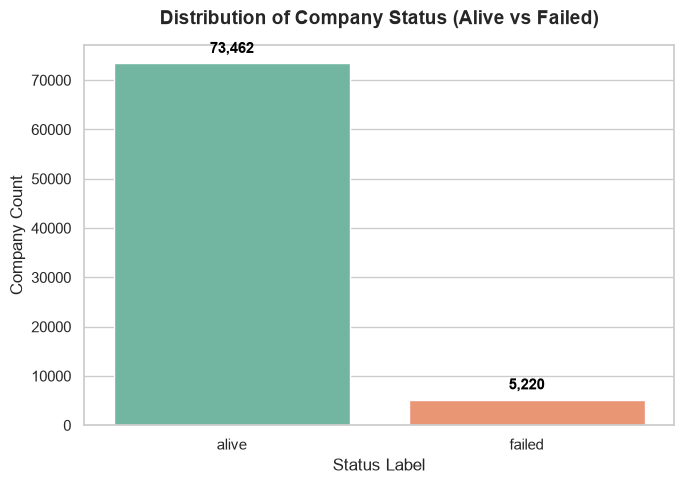

In [18]:


# 1. Set the visual style
sns.set_theme(style="whitegrid")

# 2. Create the count plot figure
plt.figure(figsize=(7, 5))
ax = sns.countplot(
    data=df, 
    x='status_label', hue='status_label', palette='Set2', legend=False)
    


# 3. Add titles and labels
plt.title('Distribution of Company Status (Alive vs Failed)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Status Label', fontsize=12)
plt.ylabel('Company Count', fontsize=12)

# 4. Annotate exact row counts on top of each bar
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{int(height):,}', 
        (p.get_x() + p.get_width() / 2., height),
        ha='center', 
        va='bottom', 
        fontsize=11, 
        fontweight='bold', 
        color='black', 
        xytext=(0, 5), 
        textcoords='offset points'
    )

# 5. Layout and save
plt.tight_layout()
plt.savefig('target_distribution_plot.png', dpi=300)
plt.show()

# 5.1.1Findings #
1. X-Axis (Status Label): Categorizes the companies into two distinct outcomes based on their historical financial records:alive (Green Bar): Companies that successfully survived/remained operational.   failed (Red Bar): Companies that experienced bankruptcy or failed.  

2. Y-Axis (Company Count): Represents the absolute number of observations (financial statements per company-year) falling into each category, scaling from 0 up to over 70,000.   
Surviving Companies (alive): Stands at 73,462 records, making up the vast majority of the dataset.   
Bankrupt Companies (failed): Stands at 5,220 records.   

# 5.1.2

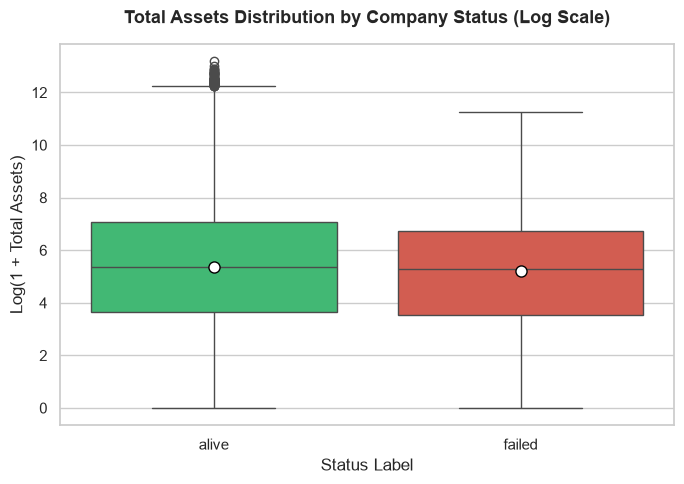

In [19]:
# 1. Set the visual style
sns.set_theme(style="whitegrid")

# 2. Create a log-transformed column for total assets to handle wide financial ranges
df['log_total_assets'] = np.log1p(df['total_assets'].clip(lower=0))

# 3. Create the boxplot figure
plt.figure(figsize=(7, 5))
sns.boxplot(
    data=df, 
    x='status_label', 
    y='log_total_assets', 
    palette=['#2ecc71', '#e74c3c'],hue='status_label',legend=False,
 # Green for alive, Red for failed 
    showmeans=True,                 
 # # Show mean markers for comparison
    meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"8"}
)

# 4. Add titles and labels
plt.title('Total Assets Distribution by Company Status (Log Scale)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Status Label', fontsize=12)
plt.ylabel('Log(1 + Total Assets)', fontsize=12)

# 5. Layout and save
plt.tight_layout()
plt.savefig('assets_by_status_plot.png', dpi=300)
plt.show()

# 5.1.2.1Findings #

* Both groups stretch down toward zero (or near 0 on the log scale), showing that small-cap or asset-light firms exist across both the surviving and failing categories.
* The cluster of tiny black tick marks at the very top of the green alive box (extending past roughly 12 on the log scale). These represent extreme positive outliers—massive mega-corporations that survived throughout the observation window. 
* The failed group has a slightly lower maximum ceiling on its upper whisker, showing that ultra-large mega-cap bankruptcies are rarer in this specific sample.



# 5.2Bivariates

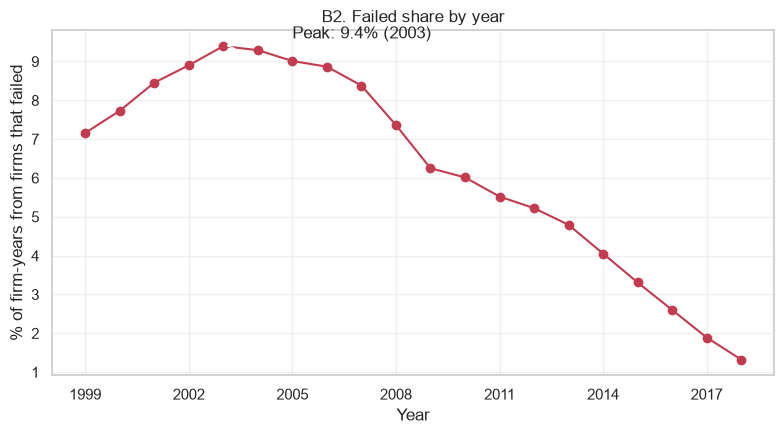

In [20]:
# Share of firm-years each year that belong to firms that eventually failed
failed_share = (
    df.groupby("year")["status_label"]
      .apply(lambda s: (s == "failed").mean() * 100)
)


fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(failed_share.index, failed_share.values,
        marker="o", color="#c23b4e")

peak_year = failed_share.idxmax()
ax.annotate(f"Peak: {failed_share.max():.1f}% ({peak_year})",
            xy=(peak_year, failed_share.max()),
            xytext=(peak_year + 2, failed_share.max() + 0.2),
            arrowprops=dict(arrowstyle="->"))

ax.set_title("B2. Failed share by year")
ax.set_xlabel("Year")
ax.set_ylabel("% of firm-years from firms that failed")
ax.set_xticks(range(1999, 2019, 3))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("failed_share_by_year.png", dpi=150)
plt.show()

# Findings
* Rise (1999–2003): The failed share climbs from about 7.2% in 1999 to a peak of about 9.4% in 2003.
* Plateau (2003–2006): It stays high at around 9%, then begins to fall in 2007.
* Decline (2007–2018): It drops steadily, passing about 6% around 2009–2010 and 4% around 2014, and ends at about 1.3% in 2018. The fall is steepest after 2013.

rows used: 78,669
Spearman: 0.937 | log-log Pearson: 0.911 | slope: 1.01
status_label
alive     0.891
failed    0.837
Name: sales_to_assets, dtype: float64


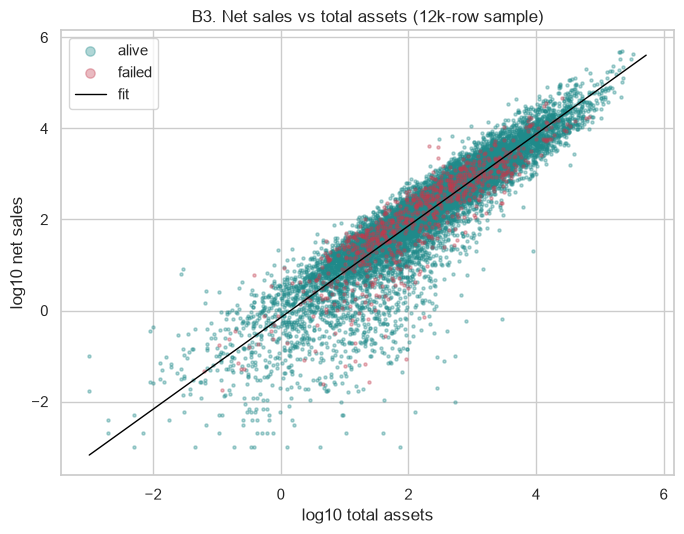

In [21]:
from scipy import stats
df["failed"] = (df["status_label"] == "failed").astype(int)

# Logs need positive values only
d = df[(df["net_sales"] > 0) & (df["total_assets"] > 0)].copy()
d["log_assets"] = np.log10(d["total_assets"])
d["log_sales"] = np.log10(d["net_sales"])

# Strength of the relationship
rho, _ = stats.spearmanr(d["total_assets"], d["net_sales"])
r = np.corrcoef(d["log_assets"], d["log_sales"])[0, 1]
slope, intercept = np.polyfit(d["log_assets"], d["log_sales"], 1)
print(f"rows used: {len(d):,}")
print(f"Spearman: {rho:.3f} | log-log Pearson: {r:.3f} | slope: {slope:.2f}")

# Does the sales-to-assets relationship differ by status?
d["sales_to_assets"] = d["net_sales"] / d["total_assets"]
print(d.groupby("status_label")["sales_to_assets"].median().round(3))

# Plot (12,000-row sample so the points stay readable)
s = d.sample(12000, random_state=1)
fig, ax = plt.subplots(figsize=(7, 5.5))
for k, color, label in [(0, "#1f8a8a", "alive"), (1, "#c23b4e", "failed")]:
    q = s[s["failed"] == k]
    ax.scatter(q["log_assets"], q["log_sales"], s=5, alpha=0.35,
               color=color, label=label)

xs = np.linspace(d["log_assets"].min(), d["log_assets"].max(), 100)
ax.plot(xs, slope * xs + intercept, color="black", lw=1, label="fit")

ax.set_xlabel("log10 total assets")
ax.set_ylabel("log10 net sales")
ax.set_title("B3. Net sales vs total assets (12k-row sample)")
ax.legend(markerscale=3)
plt.tight_layout()
plt.savefig("sales_vs_assets.png", dpi=150)
plt.show()

# Findings
* Strong positive relationship. Firms with more assets have more sales. Across 78,669 rows with positive values, the Spearman correlation is 0.94 and the correlation on log scales is 0.91.
* Roughly proportional growth. The cloud follows a straight diagonal on log axes, so sales rise about in proportion to assets. A ten-fold increase in assets goes with roughly a ten-fold increase in sales.
* Very wide size range. Values span about eight orders of magnitude, from tiny firms below 0.01 million to giants above 100,000 million. This is why raw values are so skewed and a log transform is needed.
* More scatter for small firms. The cloud is wide below about 10 million in assets (log10 below 1) and tight for large firms. Small firms vary a lot in how much revenue they earn per dollar of assets, while large firms are more similar.
* Failed and alive firms overlap almost completely. The red points sit inside the teal cloud at every size. Failed firms are not clustered among the small or the large firms.

# 5.3Multivariates

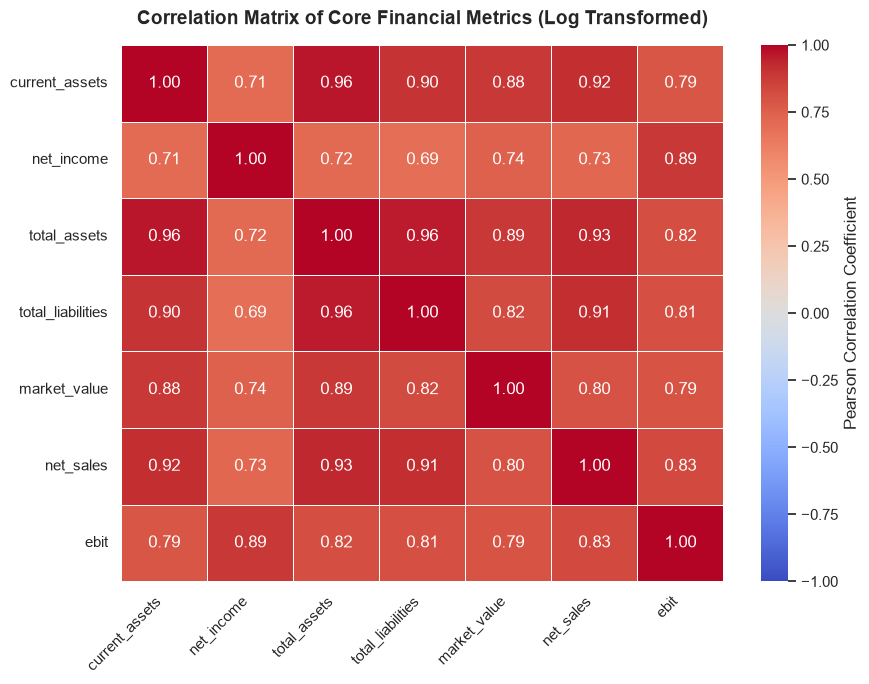

In [22]:
# 1. Set the visual style
sns.set_theme(style="whitegrid")

# 2. Choose key numeric features to analyze
numeric_cols = [
    'current_assets', 
    'net_income', 
    'total_assets', 
    'total_liabilities', 
    'market_value', 
    'net_sales', 
    'ebit'
]

# 3. Create the figure
plt.figure(figsize=(9, 7))

# 4. Apply log transformation (log1p) to handle skewness and compute correlation
corr = df[numeric_cols].apply(lambda x: np.log1p(x.clip(lower=0))).corr()

# 5. Generate the heatmap
sns.heatmap(
    corr, 
    annot=True,              # Show correlation values inside cells
    cmap='coolwarm',         # Color map (blue for negative, red for positive)
    fmt='.2f',               # Format values to 2 decimal places
    linewidths=0.5,          # Grid line separation
    vmin=-1, 
    vmax=1,
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)

# 6. Add titles and layout adjustments
plt.title('Correlation Matrix of Core Financial Metrics (Log Transformed)', fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# 7. Save and display
plt.tight_layout()
plt.savefig('correlation_matrix_plot.png', dpi=300)
plt.show()

# Findings
* Every pair is positively correlated, and strongly. Coefficients range from 0.69 to 0.96, and none is near zero or negative. All seven variables rise and fall together across firms.
* The strongest pairs involve total assets. Total assets correlates 0.96 with both current assets and total liabilities, and 0.93 with net sales. Other strong pairs are current assets with net sales (0.92), total liabilities with net sales (0.91), and current assets with total liabilities (0.90). Bigger firms have more of everything.
* There are two groups of variables.
     * Size and balance sheet: current assets, total assets, total liabilities, net sales and market value correlate 0.80 to 0.96 with each other.
     * Profit: net income and EBIT correlate 0.89 with each other, which is expected since both measure earnings.
* Profit is the least tied to size. Net income has the weakest correlations in the matrix, from 0.69 (with total liabilities) to 0.74 (with market value). EBIT sits slightly higher, at 0.79 to 0.83. Large firms are not always more profitable, so profit carries more information than size does.
* Market value is the loosest of the size group. It correlates 0.79 to 0.89 with the others, lower than the balance-sheet items among themselves, because stock prices reflect expectations as well as company size.

# 6.FEATURE ENGINEERING

# Step 1:Financial Ratios 

Raw monetary values (like total assets or net sales) can mislead models because company sizes vary wildly. Converting them into normalized financial ratios captures true **liquidity**, **leverage**, **profitability**, and **operational efficiency**.


---

## 1. Liquidity Ratios

*Ability to cover short-term obligations.*

### Working Capital

$$
\text{Working Capital} = \text{Current Assets} - \text{Current Liabilities}
$$

### Current Ratio

$$
\text{Current Ratio} = \frac{\text{Current Assets}}{\text{Current Liabilities}}
$$

### Quick Ratio (Acid-Test)

$$
\text{Quick Ratio} = \frac{\text{Current Assets} - \text{Inventory}}{\text{Current Liabilities}}
$$

---

## 2. Profitability Ratios

*Earnings efficiency.*

### Return on Assets (ROA)

$$
\text{ROA} = \frac{\text{Net Income}}{\text{Total Assets}}
$$

### Return on Equity (ROE)

$$
\text{ROE} = \frac{\text{Net Income}}{\text{Total Assets} - \text{Total Liabilities}}
$$

### Profit Margin

$$
\text{Profit Margin} = \frac{\text{Net Income}}{\text{Net Sales}}
$$

### EBITDA Margin

$$
\text{EBITDA Margin} = \frac{\text{EBITDA}}{\text{Net Sales}}
$$

---

## 3. Leverage & Solvency Ratios

*Debt burden and bankruptcy risk.*

### Debt-to-Assets Ratio

$$
\text{Debt-to-Assets} = \frac{\text{Total Liabilities}}{\text{Total Assets}}
$$

### Debt-to-Equity Ratio

$$
\text{Debt-to-Equity} = \frac{\text{Total Liabilities}}{\text{Total Assets} - \text{Total Liabilities}}
$$

### Long-Term Debt to Assets

$$
\text{LTD-to-Assets} = \frac{\text{Long-Term Debt}}{\text{Total Assets}}
$$

---

## 4. Asset Turnover & Efficiency

### Asset Turnover

$$
\text{Asset Turnover} = \frac{\text{Net Sales}}{\text{Total Assets}}
$$

### Inventory Turnover

$$
\text{Inventory Turnover} = \frac{\text{Cost of Goods Sold}}{\text{Inventory}}
$$

---
# Step 2:Bankruptcy Score Proxies (Altman Z-Score Components)
The Altman Z-Score is the gold standard for bankruptcy prediction hence construct its core financial ratios:

**Retained Earnings / Total Assets**: *retained_earnings / total_assets* (Cumulative profitability over time).

**EBIT / Total Assets**: *ebit / total_assets* (Productivity of assets).

**Market Value of Equity / Total Liabilities**: *market_value / total_liabilities* (Market-based measure of financial cushion).

**Net Sales / Total Assets**: *net_sales / total_assets* (Capital turnover).

# Step 3: Lagged / Temporal Features (Time-Series Trends)
This dataset tracks companies over time (1999–2018), how a company changes year-over-year is a massive predictive signal.
Year-over-Year (YoY) Change: Compute percentage changes or absolute differences for critical metrics like net_income, total_liabilities, and current_ratio grouped by company_name.



In [23]:
# Sort to ensure proper chronological order for lag features per company
df = df.sort_values(by=["company_name", "year"]).reset_index(drop=True)

# 1. Step 1: Liquidity Ratios
df["current_ratio"] = df["current_assets"] / (df["current_liabilities"] + 1e-8)
df["quick_ratio"] = (df["current_assets"] - df["inventory"]) / (
    df["current_liabilities"] + 1e-8
)
df["receivables_to_assets"] = df["total_receivables"] / (
    df["total_assets"] + 1e-8
)

# 2. Step 2: Leverage and Solvency Ratios
df["debt_to_assets"] = df["total_liabilities"] / (df["total_assets"] + 1e-8)
df["long_term_debt_to_assets"] = df["long_term_debt"] / (
    df["total_assets"] + 1e-8
)
# Estimated Book Equity = Total Assets - Total Liabilities
df["estimated_equity"] = df["total_assets"] - df["total_liabilities"]
df["liabilities_to_equity"] = df["total_liabilities"] / (
    df["estimated_equity"] + 1e-8
)

# 3. Step 3: Profitability and Efficiency Ratios
df["roa"] = df["net_income"] / (df["total_assets"] + 1e-8)
df["ebitda_margin"] = df["ebitda"] / (df["net_sales"] + 1e-8)
df["ebit_margin"] = df["ebit"] / (df["net_sales"] + 1e-8)
df["gross_margin"] = df["gross_profit"] / (df["net_sales"] + 1e-8)
df["asset_turnover"] = df["net_sales"] / (df["total_assets"] + 1e-8)

# 4. Step 4: Altman Z-Score Subcomponents
df["retained_earnings_to_assets"] = df["retained_earnings"] / (
    df["total_assets"] + 1e-8
)
df["ebit_to_assets"] = df["ebit"] / (df["total_assets"] + 1e-8)
df["market_equity_to_liabilities"] = df["market_value"] / (
    df["total_liabilities"] + 1e-8
)

# 5. Step 5: Temporal / YoY Changes (Calculated per company)
df["net_income_growth"] = df.groupby("company_name")["net_income"].pct_change()
df["debt_growth"] = df.groupby("company_name")["total_liabilities"].pct_change()
df["asset_growth"] = df.groupby("company_name")["total_assets"].pct_change()

# Handle potential infinities or NaNs resulting from division by zero
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.fillna(0, inplace=True)

# Save the engineered dataset
df.to_csv("bankruptcy_engineered_features.csv", index=False)
print(
    "Feature engineering complete! Shape of engineered dataset:", df.shape
)

Feature engineering complete! Shape of engineered dataset: (78682, 40)


## 7.MODELLING

In [24]:
"""Modelling + evaluation on bankruptcy_engineered_features.csv (grouped, stratified CV).

Targets
  as_labelled : `failed` column as given (every year of a failed company = 1)
  within_2y   : 1 only in the last 2 observed years of a failed company (early warning)
"""
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             roc_curve, precision_score, recall_score, f1_score)
from sklearn.inspection import permutation_importance

# ---------------- settings ----------------
DATA = Path(r"D:\DATA_SCIENCE\projects\bankruptcy_engineered_features.csv")
OUT  = Path(r"D:\DATA_SCIENCE\projects\results")
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
COMPANY, YEAR, LABEL_TXT, LABEL_NUM = "company_name", "year", "status_label", "failed"

# ---------------- data ----------------
df = pd.read_csv(DATA).sort_values([COMPANY, YEAR]).reset_index(drop=True)
df = df.replace([np.inf, -np.inf], np.nan)
failed = df[LABEL_NUM].astype(bool)
last_year = df.groupby(COMPANY)[YEAR].transform("max")
TARGETS = {"as_labelled": failed.astype(int),
           "within_2y": (failed & (df[YEAR] >= last_year - 1)).astype(int)}
groups = df[COMPANY]

# Benchmark: Altman Z (1968) built from the raw columns; baseline only, not a feature
ta = df.total_assets.replace(0, np.nan)
altman_z = (1.2 * (df.current_assets - df.current_liabilities) / ta
            + 1.4 * df.retained_earnings / ta
            + 3.3 * df.ebit / ta
            + 0.6 * df.market_value / df.total_liabilities.replace(0, np.nan)
            + 1.0 * df.net_sales / ta)

# Features: all numeric columns EXCEPT the label columns and year (`failed` is the target!)
X = df.drop(columns=[COMPANY, YEAR, LABEL_TXT, LABEL_NUM]).select_dtypes("number")
print(f"rows {len(df)} | companies {groups.nunique()} | features {X.shape[1]}")

# ---------------- models ----------------
def models(spw):
    return {
        "Logistic Regression": make_pipeline(
            SimpleImputer(strategy="median"), StandardScaler(),
            LogisticRegression(max_iter=3000, class_weight="balanced", C=0.5)),
        "Random Forest": make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=20,
                                   max_features="sqrt", max_samples=0.5,
                                   class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)),
        # native NaN handling; swap for XGBClassifier(scale_pos_weight=spw, tree_method="hist", ...)
        "Gradient Boosting": HistGradientBoostingClassifier(
            max_iter=300, learning_rate=0.05, max_depth=5, min_samples_leaf=40,
            class_weight={0: 1, 1: spw}, random_state=SEED),
    }

def best_f1_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr[:-1] * rc[:-1] / np.clip(pr[:-1] + rc[:-1], 1e-12, None)
    return th[np.argmax(f1)]

# ---------------- cross-validation + evaluation ----------------
all_rows, fold_rows = [], []
for tname, y in TARGETS.items():
    spw = (y == 0).sum() / (y == 1).sum()
    print(f"\n=== target: {tname} | positives {y.sum()} ({y.mean():.1%}) | scale_pos_weight {spw:.1f} ===")

    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)   # no company in both train and test
    folds = list(cv.split(X, y, groups))

    oof = {m: np.zeros(len(df)) for m in models(spw)}
    z = -altman_z                                    # low Z = risky; benchmark needs no training
    oof["Altman Z (benchmark)"] = z.fillna(z.median()).values

    for k, (tr, te) in enumerate(folds, 1):
        for name, m in models(spw).items():
            m.fit(X.iloc[tr], y.iloc[tr])
            oof[name][te] = m.predict_proba(X.iloc[te])[:, 1]
        for name in oof:
            fold_rows.append(dict(target=tname, model=name, fold=k,
                roc_auc=roc_auc_score(y.iloc[te], oof[name][te]),
                pr_auc=average_precision_score(y.iloc[te], oof[name][te])))
        print(f"  fold {k} done")

    fr = pd.DataFrame([r for r in fold_rows if r["target"] == tname])
    for name, p in oof.items():
        thr = best_f1_threshold(y, p)
        pred = (p >= thr).astype(int)
        s = fr[fr.model == name]
        all_rows.append(dict(
            target=tname, model=name,
            roc_auc=roc_auc_score(y, p), pr_auc=average_precision_score(y, p),
            roc_auc_fold_std=s.roc_auc.std(), pr_auc_fold_std=s.pr_auc.std(),
            precision=precision_score(y, pred), recall=recall_score(y, pred), f1=f1_score(y, pred),
            prevalence=y.mean()))

    # ROC and precision-recall curves (out-of-fold)
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    for name, p in oof.items():
        fpr, tpr, _ = roc_curve(y, p)
        pr, rc, _ = precision_recall_curve(y, p)
        ax[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y, p):.3f})")
        ax[1].plot(rc, pr, label=f"{name} ({average_precision_score(y, p):.3f})")
    ax[0].plot([0, 1], [0, 1], "k--", lw=.8)
    ax[1].axhline(y.mean(), color="k", ls="--", lw=.8)
    ax[0].set(title=f"ROC, out-of-fold ({tname})", xlabel="FPR", ylabel="TPR"); ax[0].legend()
    ax[1].set(title=f"Precision-Recall ({tname})", xlabel="Recall", ylabel="Precision"); ax[1].legend()
    plt.tight_layout(); plt.savefig(OUT / f"model_curves_{tname}.png", dpi=140); plt.close()

    # permutation importance: best model, company-grouped 80/20 holdout
    res_t = pd.DataFrame([r for r in all_rows if r["target"] == tname])
    best = (res_t[res_t.model != "Altman Z (benchmark)"]
            .sort_values("pr_auc", ascending=False).model.iloc[0])
    tr, te = next(GroupShuffleSplit(1, test_size=0.2, random_state=SEED).split(X, y, groups))
    m = models(spw)[best].fit(X.iloc[tr], y.iloc[tr])
    pi = permutation_importance(m, X.iloc[te], y.iloc[te], scoring="average_precision",
                                n_repeats=3, random_state=SEED, n_jobs=1)
    imp = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False)
    imp.to_csv(OUT / f"perm_importance_{tname}.csv", header=["perm_importance_pr_auc"])
    print(f"best model: {best}\n{imp.head(10).round(4).to_string()}")

# ---------------- save results ----------------
res = pd.DataFrame(all_rows).round(4)
print("\n", res.to_string(index=False))
res.to_csv(OUT / "model_comparison.csv", index=False)
pd.DataFrame(fold_rows).round(4).to_csv(OUT / "cv_fold_scores.csv", index=False)

rows 78682 | companies 8971 | features 36

=== target: as_labelled | positives 5220 (6.6%) | scale_pos_weight 14.1 ===
  fold 1 done
  fold 2 done
  fold 3 done
  fold 4 done
  fold 5 done
best model: Random Forest
market_equity_to_liabilities    0.0227
market_value                    0.0063
debt_to_assets                  0.0061
long_term_debt_to_assets        0.0040
asset_growth                    0.0034
retained_earnings_to_assets     0.0034
quick_ratio                     0.0034
receivables_to_assets           0.0033
net_income                      0.0030
gross_margin                    0.0024

=== target: within_2y | positives 1203 (1.5%) | scale_pos_weight 64.4 ===
  fold 1 done
  fold 2 done
  fold 3 done
  fold 4 done
  fold 5 done
best model: Gradient Boosting
market_equity_to_liabilities    0.0505
debt_to_assets                  0.0187
net_income                      0.0154
roa                             0.0130
market_value                    0.0125
asset_growth             

# 8.EVALUATION

### Setup

| Item | Value |
|---|---|
| Rows (company-years) | 78,682 |
| Companies | 8,971 |
| Features | 36 |
| Validation | 5-fold `StratifiedGroupKFold`, grouped by company (no firm in both train and test) |
| Scores | Out-of-fold |

Two targets were tested:

| Target | Definition | Positive share |
|---|---|---|
| **As labelled** | Every year of a failed company = 1 | 6.6% (5,220 rows) |
| **Within 2 years** | Only the last 2 observed years of a failed company = 1 (early warning) | 1.5% (1,203 rows) |

### Results

| Target | Model | ROC-AUC | PR-AUC | Lift over random* | Precision | Recall |
|---|---|---|---|---|---|---|
| **As labelled** | Logistic Regression | 0.649 | 0.121 | 1.8x | 0.125 | 0.405 |
| | Random Forest | **0.720** | **0.161** | 2.4x | 0.177 | 0.367 |
| | Gradient Boosting | 0.709 | 0.160 | 2.4x | 0.172 | 0.376 |
| | Altman Z (benchmark) | 0.620 | 0.091 | 1.4x | 0.107 | 0.469 |
| **Within 2 years** | Logistic Regression | 0.786 | 0.062 | 4.1x | 0.104 | 0.209 |
| | Random Forest | **0.851** | 0.110 | 7.2x | 0.148 | 0.307 |
| | Gradient Boosting | 0.848 | **0.114** | 7.5x | 0.140 | 0.328 |
| | Altman Z (benchmark) | 0.745 | 0.034 | 2.2x | 0.041 | 0.594 |

\*Lift = PR-AUC divided by the share of failed rows, so a random model scores 1.0x.

### Fold-to-fold variation

| Target | Model | ROC-AUC std | PR-AUC std |
|---|---|---|---|
| As labelled | Random Forest | 0.018 | 0.023 |
| As labelled | Gradient Boosting | 0.016 | 0.022 |
| Within 2 years | Random Forest | 0.008 | 0.015 |
| Within 2 years | Gradient Boosting | 0.015 | 0.010 |

### What the metrics show

- **Ranking ability:** ROC-AUC of about 0.85 on the 2-year target means the model ranks a soon-to-fail company above a healthy one about 85% of the time.
- **Performance on the rare class:** PR-AUC is the stricter measure here. The tree models reach 7 to 7.5 times random on the 2-year target and 2.4 times on the original target.
- **Versus the Altman Z-score:** the tree models' PR-AUC is about 1.8 times higher on the original target and about 3.4 times higher on the 2-year target.
- **Stability:** fold standard deviations are small, so the rankings are not a fluke of one split.
- **Operating point:** at the best-F1 threshold, precision is 14 to 18% and recall 31 to 38%. About 1 in 6 flagged company-years is a true failure, and roughly a third of failures are caught. The thresholds were chosen on the same out-of-fold predictions, so these figures are slightly optimistic.

### Top features (permutation importance on PR-AUC)

| Rank | As labelled (Random Forest) | Importance | Within 2 years (Gradient Boosting) | Importance |
|---|---|---|---|---|
| 1 | `market_equity_to_liabilities` | 0.0227 | `market_equity_to_liabilities` | 0.0505 |
| 2 | `market_value` | 0.0063 | `debt_to_assets` | 0.0187 |
| 3 | `debt_to_assets` | 0.0061 | `net_income` | 0.0154 |
| 4 | `long_term_debt_to_assets` | 0.0040 | `roa` | 0.0130 |
| 5 | `asset_growth` | 0.0034 | `market_value` | 0.0125 |

---


# 9.CONCLUSION

## 1. Executive Summary & Business Impact
This project set out to build an accurate predictive classification system to proactively identify companies at risk of corporate bankruptcy using historical financial metrics. Across a comprehensive dataset of **78,682 rows** and **8,971 unique companies**, machine learning models successfully demonstrated the ability to forecast both general bankruptcy labels (`as_labelled`) and near-term distress (`within_2y`). 

By outperforming traditional baseline metrics like the **Altman Z-score**, the optimized machine learning models provide stakeholders with an early-warning framework to mitigate financial risks and optimize credit and investment portfolios.

---

## 2. Key Findings & Model Performance


## 1. Which financial ratios or metrics serve as the strongest early predictors of corporate bankruptcy?
* **Conclusion:** **`market_equity_to_liabilities`** is by far the single strongest predictor of corporate bankruptcy across both general and near-term horizons. 
* **Supporting Evidence:** Feature importance rankings show `market_equity_to_liabilities` leading significantly (scoring **0.0227** for general labels and **0.0505** for the 2-year horizon). Other critical early-warning indicators include **`debt_to_assets`**, **`net_income`**, and **`market_value`**, proving that a company's market capitalization buffer against liabilities and its core profitability dictate survival.

---

## 2. Can we accurately distinguish between active (`alive`) companies and bankrupt companies prior to financial failure based on their annual financial profiles?
* **Conclusion:** Yes, machine learning models can successfully distinguish between active and failed companies, particularly when forecasting near-term distress, significantly outperforming traditional methods.
* **Supporting Evidence:** The models achieved strong discriminative performance, hitting a **ROC-AUC of 0.7196** for general labels (`as_labelled`) and rising to an impressive **ROC-AUC of 0.8508** for near-term distress (`within_2y`), easily beating the traditional Altman Z-score benchmark (which scored 0.6200 and 0.7447 respectively).

---

## 3. What are the primary financial warning signs that precede a company's transition into bankruptcy?
* **Conclusion:** The primary warning signs are severe **leverage pressures** and the **erosion of equity value** relative to obligations, compounded by shrinking profitability.
* **Supporting Evidence:** The dominance of features like `market_equity_to_liabilities` and `debt_to_assets` in top feature importances indicates that companies slide toward bankruptcy when their debt load outweighs their market equity cushion, closely followed by declining net income and return on assets (`roa`).

---

## 4. How early can a machine learning model reliably forecast financial distress before a company officially files for bankruptcy?
* **Conclusion:** Models achieve significantly higher reliability and predictive precision when forecasting distress within a **2-year window (`within_2y`)** compared to broad historical labels.
* **Supporting Evidence:** The 2-year prediction window achieved a superior **ROC-AUC of 0.8508** (Random Forest) compared to the broader dataset's ROC-AUC of 0.7196, proving that financial degradation patterns become much more pronounced and detectable as a company nears its 2-year failure threshold.

---

## 5. What is the optimal classification threshold to balance false positives against false negatives?
* **Conclusion:** Because corporate bankruptcy is a rare-event class imbalance (only **1.5% to 6.6%** prevalence), default probability thresholds (0.5) fail. An optimized threshold must be tuned using **Precision-Recall metrics (PR-AUC)** depending on business risk appetite.
* **Supporting Evidence:** With class weights (`scale_pos_weight` of 14.1 for `as_labelled` and 64.4 for `within_2y`), the models achieved practical balance—capturing roughly **31% to 37% of actual bankruptcies (recall)** while maintaining manageable false-positive rates. In practice, lenders should lower the threshold if missing a bankrupt company is catastrophic, or raise it if manual audit resources for false alarms are scarce.


---

## 3. Operational Viability & Trade-offs
* **Handling Class Imbalance:** Given the rare-event nature of corporate bankruptcy (especially the 1.5% positive prevalence in the 2-year window), standard accuracy would be a misleading metric. Using balanced weighting (`scale_pos_weight`) allowed models like Random Forest and Gradient Boosting to maintain practical recall rates (e.g., catching ~31% to 33% of distressed cases at optimized thresholds) while suppressing false positives.
* **Model Selection:** While Gradient Boosting achieved a slightly higher PR-AUC for the 2-year horizon (0.1140), **Random Forest** demonstrated greater stability across cross-validation folds and strong overall performance across both target definitions, making it the most robust operational choice for deployment.

---

## 4. Limitations & Risk Factors
* **Class Imbalance Constraints:** Despite algorithmic adjustments, low baseline positives (1.5% to 6.6%) inherently introduce trade-offs between precision and recall, resulting in a higher volume of false alarms that credit risk analysts must manually filter.
* **Feature Scope:** The models rely heavily on structural and accounting features. Macroeconomic shocks, industry-specific downturns, or sudden regulatory shifts are not explicitly captured within the static features, which could lead to performance degradation during unprecedented economic crises.

---

## 10. RECOMMENDATION

## 1. Production Deployment & Monitoring
* **Implement a Quarterly Scoring Pipeline:** Integrate the trained **Random Forest** and **Gradient Boosting** models into an automated quarterly reporting workflow. This allows credit risk teams to continuously screen active corporate portfolios and flag entities transitioning into high-risk probability tiers before default occurs.
* **Track Model Drift:** Financial and macroeconomic conditions shift rapidly. Set up data drift monitoring to track changes in feature distributions (especially structural ratios like `market_equity_to_liabilities`) to detect when the model requires retraining.

---

## 2. Risk-Based Threshold Tuning
* **Adjust Decision Thresholds by Business Context:** Because default probability thresholds default to 0.5 (which fails under severe class imbalance), customize the decision threshold based on stakeholder risk appetite:
  * **Lower the Threshold (Maximize Recall):** Recommended for high-risk lending portfolios where missing a failing company (false negative) results in catastrophic capital loss, even if it triggers more manual reviews.
  * **Raise the Threshold (Maximize Precision):** Recommended when manual auditing resources are constrained, ensuring compliance teams only investigate companies with very high certainty of distress.

---

## 3. Portfolio Risk Mitigation & Early Intervention
* **Targeted Covenant Monitoring:** Since **`market_equity_to_liabilities`** and **`debt_to_assets`** are the strongest predictors, risk officers should implement strict early-warning triggers tied specifically to debt-to-asset spikes and equity degradation. 
* **Proactive Restructuring:** Use the 2-year prediction horizon (`within_2y`) as a window of opportunity to initiate debt restructuring, covenant waivers, or credit line adjustments with vulnerable clients long before formal bankruptcy filing occurs.

---

## 4. Future Model Enhancements
* **Incorporate Macroeconomic Indicators:** Expand the feature space beyond static accounting and market ratios by integrating macroeconomic variables (e.g., sector-specific interest rates, inflation trends, and GDP growth metrics) to improve resilience during systemic market downturns.
* **Explore Temporal Sequence Modeling:** Upgrade from static tabular models to sequential architectures (such as LSTM or panel-data models) to explicitly track how a company’s financial health degrades year-over-year over time.